In [1]:
import numpy as np
import os
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from scipy.optimize import curve_fit
import energycal
indices = {
    0: (4, 0),
    1: (4, 1),
    2: (7, 2),
    3: (5, 0),
    4: (5, 3),
    5: (5, 2),
    6: (4, 3),
    7: (7, 0),
    8: (6, 1),
    9: (7, 3),
    10: (5, 1),
    11: (6, 3),
    12: (4, 2),
    13: (6, 2),
    14: (6, 0),
    15: (7, 1),
    16: (3, 0),
    17: (3, 1),
    18: (2, 0),
    19: (2, 1),
    20: (0, 0),
    21: (1, 0),
    22: (0, 1),
    23: (1, 1),
    24: (3, 2),
    25: (1, 2),
    26: (2, 2),
    27: (4, 4),
    28: (0, 2),
    29: (3, 3),
    30: (0, 3),
    31: (1, 3),
    32: (2, 3),
    33: (3, 4),
    34: (2, 4),
    35: (0, 4),
    36: (1, 4),
    37: (0, 5),
    38: (5, 4),
    39: (1, 5),
    40: (2, 5),
    41: (3, 5),
    42: (1, 6),
    43: (0, 6),
    44: (0, 7),
    45: (3, 6),
    46: (1, 7),
    47: (2, 6),
    48: (3, 7),
    49: (2, 7),
    50: (6, 5),
    51: (6, 6),
    52: (7, 6),
    53: (4, 6),
    54: (5, 6),
    55: (6, 7),
    56: (7, 7),
    57: (7, 5),
    58: (7, 4),
    59: (4, 5),
    60: (5, 7),
    61: (5, 5),
    62: (6, 4),
    63: (4, 7),
    64: (11, 7),
    65: (11, 6),
    66: (10, 4),
    67: (10, 6),
    68: (11, 4),
    69: (9, 7),
    70: (9, 5),
    71: (8, 7),
    72: (9, 6),
    73: (11, 3),
    74: (10, 7),
    75: (10, 3),
    76: (11, 5),
    77: (8, 5),
    78: (10, 5),
    79: (8, 6),
    80: (12, 7),
    81: (14, 7),
    82: (13, 7),
    83: (15, 7),
    84: (13, 6),
    85: (12, 6),
    86: (14, 6),
    87: (15, 6),
    88: (12, 5),
    89: (14, 5),
    90: (13, 5),
    91: (9, 4),
    92: (15, 5),
    93: (15, 4),
    94: (14, 4),
    95: (12, 4),
    96: (13, 4),
    97: (13, 3),
    98: (14, 3),
    99: (12, 3),
    100: (15, 3),
    101: (15, 2),
    102: (8, 4),
    103: (14, 2),
    104: (15, 1),
    105: (13, 2),
    106: (14, 1),
    107: (12, 2),
    108: (15, 0),
    109: (13, 1),
    110: (14, 0),
    111: (12, 1),
    112: (13, 0),
    113: (12, 0),
    114: (8, 2),
    115: (10, 1),
    116: (8, 1),
    117: (11, 1),
    118: (9, 1),
    119: (9, 0),
    120: (8, 0),
    121: (9, 2),
    122: (9, 3),
    123: (11, 2),
    124: (10, 0),
    125: (10, 2),
    126: (8, 3),
    127: (11, 0)
}

def find_relevents(chunk, lookat, targetid = None, include = 0):
    counter, index = 0, 0
    while counter < lookat:
        counter += 1
        while np.abs(chunk[index]['time'] - chunk[index+1]['time']) < 10000:
            index += 1
        index += 1
    include = 0
    if include == 0:
        while np.abs(chunk[index + include]['time'] - chunk[index + include + 1]['time']) < 10000:
            include += 1
    nexttime = chunk[index + include + 1]['time']
    return chunk[index:index + include + 1], nexttime, len(chunk[index:index + include + 1])
def print_relevents(relevents):
    t0 = relevents[0]['time']
    for row in relevents:
        id = row['id'] % 128
        x, y = indices[id][0], indices[id][1]
        print(f'{row[0] - t0} \t {row[1]:.2f} \t {row[2]} \t {id} \t {x} \t {y}')

def make_sipmhm(relevents):
    origin, t0, id0 = None, None, None
    sipmhm = np.zeros((7, 7))
    sipmtime = np.zeros((7, 7))
    for row in relevents:
        id = row['id'] % 128
        x, y = indices[id][0], indices[id][1]

        if origin is None:
            origin = (x, y)
            sipmhm[3, 3] = row['energy']
            t0 = row['time']
            id0 = id
        else:
            try:
                sipmhm[x - origin[0] + 3, y - origin[1] + 3] = row['energy']
                sipmtime[x - origin[0] + 3, y - origin[1] + 3] = row['time'] - t0
            except:
                pass
    for id in range(128):
        all_valid_coords = set((x - origin[0] + 3, y - origin[1] + 3) for (x, y) in indices.values() 
                               if (x - origin[0] + 3) in range(7) and (y - origin[1] + 3) in range(7))
        for i in range(7):
            for j in range(7):
                if (i, j) not in all_valid_coords:
                    sipmhm[i, j] = -1
 
    plt.figure(figsize=(4, 4))
    # conditionally mask dead channels before plotting
    dead_channel_mask = (sipmhm == -1)  # example: dead channels have zero energy
    display_array = np.ma.masked_where(dead_channel_mask, sipmhm)
    plt.imshow(display_array, cmap='jet', vmin=0, vmax=30, alpha=0.6)
    for i in range(7):
        for j in range(7):
            if sipmhm[i, j] != -1:
                plt.text(j, i, f'{sipmhm[i, j]:.2f}\n{int(sipmtime[i, j])}',
                         ha='center', va='center', fontsize=8)
    # plt.colorbar(shrink = 0.5)
    plt.axis('off')
    plt.show()
GETCOLORSCALE = 30
def get_color(energy):
    return plt.cm.jet(np.min([energy / GETCOLORSCALE, 1]))
def make_sipmhm_whole(relevents):
    energiesL = np.zeros(128)
    timesL = np.zeros(128)
    energiesR = np.zeros(128)
    timesR = np.zeros(128)
    t0 = relevents[0]['time']
    for row in relevents:
        id_val = row['id']
        if 128 <= (id_val % 256) <= 255:
            idx = (id_val % 256) - 128
            energiesL[idx] += row['energy']
            timesL[idx] += row['time'] - t0
        elif 0 <= (id_val % 256) <= 127:
            idx = id_val % 256
            energiesR[idx] += row['energy']
            timesR[idx] += row['time'] - t0
    fig, axs = plt.subplots(1, 2, figsize=(8, 8), gridspec_kw={'width_ratios': [1, 1]})
    axL = axs[0]
    for n in range(128):
        y, x = indices[n]
        y_ = 15 - y
        if y_ >= 8:
            y_ += 0.4
        rect = patches.Rectangle((x, y_), 1, 1, linewidth=0, facecolor=get_color(energiesL[n]), alpha=0.6)
        axL.add_patch(rect)
        axL.text(x + 0.5, y_ + 0.5, f'{energiesL[n]:.2f}\n{int(timesL[n])}', fontsize=8, ha='center', va='center')
    axL.axis('off')
    axL.set_ylim(0, 16.4)
    axL.set_xlim(0, 8)
    axL.set_aspect('equal')
    axR = axs[1]
    for n in range(128):
        y, x = indices[n]
        y_ = 15 - y
        if y_ >= 8:
            y_ += 0.4
        rect = patches.Rectangle((x, y_), 1, 1, linewidth=0, facecolor=get_color(energiesR[n]), alpha=0.6)
        axR.add_patch(rect)
        axR.text(x + 0.5, y_ + 0.5, f'{energiesR[n]:.2f}\n{int(timesR[n])}', fontsize=8, ha='center', va='center')
    axR.axis('off')
    axR.set_ylim(0, 16.4)
    axR.set_xlim(0, 8)
    axR.set_aspect('equal')
    plt.show()

In [ ]:
#path = '/home/kale-chen/Documents/PET/MDA_04112026/run1singles.ldat'
#path = '/home/kale-chen/Documents/PET/MiniPET/singles/old/Run118_singles.ldat'
path = 'data/testcoinc.bin'
#path = 'data/testtarget29.bin'
#path = 'data/joint_filter_testtarget29.bin'
row_size = 16
num_rows = os.path.getsize(path) // row_size
dtypes = np.dtype([('time', np.int64), 
                    ('energy', np.float32), 
                    ('id', np.int32)])
data = np.memmap(path, dtype=dtypes, mode='r', shape=(num_rows,))
print(data[0:3])
print(num_rows)

[(6470975042476, 21.784122 , 262774) (6470975042278, 17.4608   , 262780)
 (6470975046675,  1.1360435, 262769)]
378660615


In [40]:
chunk = data[:10000000]
uniqueids = np.unique(chunk['id'] % 1024)
print(len(uniqueids))

for i in range(0, len(data), 10000000):
    chunk = np.array(data[i:i+10000000])
    chunk['id'] = chunk['id'] % 1024
    #chunk['id'][chunk['id'] < 512] = chunk['id'][chunk['id'] < 512] - 256
    #chunk['id'][chunk['id'] >= 512] = chunk['id'][chunk['id'] >= 512] - 384
    print(chunk[0:20])
    break

256
[(6470975042476, 21.784122  , 630) (6470975042278, 17.4608    , 636)
 (6470975046675,  1.1360435 , 625) (6470975043974,  3.0622063 , 639)
 (6470975043740,  5.703537  , 628) (6470975044151,  5.2943954 , 627)
 (6470975045255,  5.381584  , 631) (6470975046287,  1.7317734 , 637)
 (6470975047424,  3.035366  , 633) (6470975049811,  1.427597  , 629)
 (6470975051405,  1.2085114 , 626) (6470975048505,  2.192131  , 632)
 (6470975056766,  0.691597  , 623) (6471068816690,  5.4535294 , 513)
 (6471068815780, 19.37328   , 529) (6471068817879,  4.1793633 , 531)
 (6471068820010,  2.268406  , 528) (6471068817172,  2.1339111 , 536)
 (6471068825587,  1.1515923 , 522) (6471068822761,  0.47577667, 530)]


In [41]:
targetid = 222
eventcounts = 0
for i in tqdm(range(0, len(data), 10000000)):
    chunk = np.array(data[i:i+10000000])
    chunk['id'] = chunk['id'] % 1024
    chunk['id'][chunk['id'] < 512] = chunk['id'][chunk['id'] < 512] - 256
    chunk['id'][chunk['id'] >= 512] = chunk['id'][chunk['id'] >= 512] - 384
    chunk = chunk[chunk['id'] == targetid]
    eventcounts += len(chunk)
energies = np.zeros(eventcounts)
writehead = 0
for i in tqdm(range(0, len(data), 10000000)):
    chunk = np.array(data[i:i+10000000])
    chunk['id'] = chunk['id'] % 1024
    chunk['id'][chunk['id'] < 512] = chunk['id'][chunk['id'] < 512] - 256
    chunk['id'][chunk['id'] >= 512] = chunk['id'][chunk['id'] >= 512] - 384
    chunk = chunk[chunk['id'] == targetid]
    energies[writehead:writehead+len(chunk)] = chunk['energy']
    writehead += len(chunk)
print(eventcounts)

 58%|█████▊    | 22/38 [00:13<00:09,  1.62it/s]


KeyboardInterrupt: 

ValueError: x and y must have same first dimension, but have shapes (100,) and (256, 100)

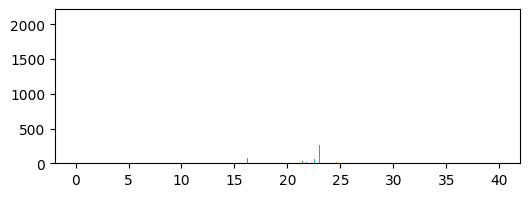

In [ ]:
def gaussian(x, a, mu, c):
    return a * np.exp(-(x - mu)**2 / (2 * c**2))
plt.figure(figsize=(6, 2))
hist, bins = plt.hist(energies, bins=100, range=(0, 40))[0:2]
bincenters = (bins[:-1] + bins[1:]) / 2
hist[:50] = 0
plt.plot(bincenters, hist)
max_idx = np.argmax(hist)
fit_width = 3
fr = (np.argmax(hist)-fit_width, np.argmax(hist)+fit_width)
popt, pcov = curve_fit(
    gaussian,
    bincenters[fr[0]:fr[1]],
    hist[fr[0]:fr[1]],
    p0=[max(hist[fr[0]:fr[1]]), bincenters[max_idx], 2]
)
plt.plot(bincenters[fr[0]:fr[1]], gaussian(bincenters[fr[0]:fr[1]], *popt))
plt.yscale('log')
print(popt)
plt.show()

In [43]:
photopeaks = np.fromfile('photopeaks.bin')
escalars = energycal.obtainscalars(photopeaks)


28.413083350196178 14.91578172744026


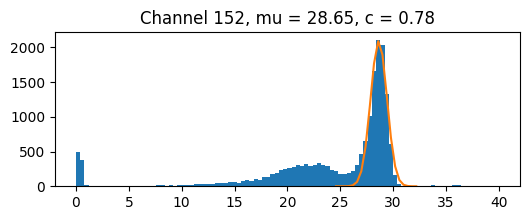

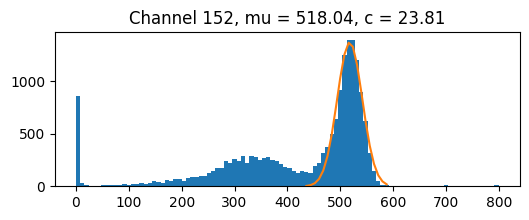

In [47]:
randid = np.random.randint(0, 256)
print(photopeaks[randid], escalars[randid])
#randid = 157
def gaussian(x, a, mu, c):
    return a * np.exp(-(x - mu)**2 / (2 * c**2))
plt.figure(figsize=(6, 2))
hist, bins = plt.hist(energies[randid], bins=100, range=(0, 40))[0:2]
bincenters = (bins[:-1] + bins[1:]) / 2
popt, fr = energycal.fitphotopeak(energies[randid])
plt.plot(bincenters[fr[0]:fr[1]], gaussian(bincenters[fr[0]:fr[1]], *popt))
plt.title(f'Channel {randid}, mu = {popt[1]:.2f}, c = {popt[2]:.2f}')
plt.show()
energiescal = energycal.convertenergy(np.array(energies[randid]), escalars[randid])
plt.figure(figsize=(6, 2))
hist, bins = plt.hist(energiescal, bins=100, range=(0, 800))[0:2]
bincenters = (bins[:-1] + bins[1:]) / 2
fr = (np.argmax(hist[10:])-10 + 10, np.argmax(hist[10:])+10 + 10)
popt, _ = curve_fit(gaussian, bincenters[fr[0]:fr[1]], hist[fr[0]:fr[1]], p0=[max(hist[fr[0]:fr[1]]), bincenters[fr[0] + np.argmax(hist[fr[0]:fr[1]])], 2])
plt.plot(bincenters[fr[0]:fr[1]], gaussian(bincenters[fr[0]:fr[1]], *popt))
plt.title(f'Channel {randid}, mu = {popt[1]:.2f}, c = {popt[2]:.2f}')
plt.show()


In [9]:
lookat = 0
GETCOLORSCALE = 600

[0.8471718]
21 1088096637915044 1
[9.303943]


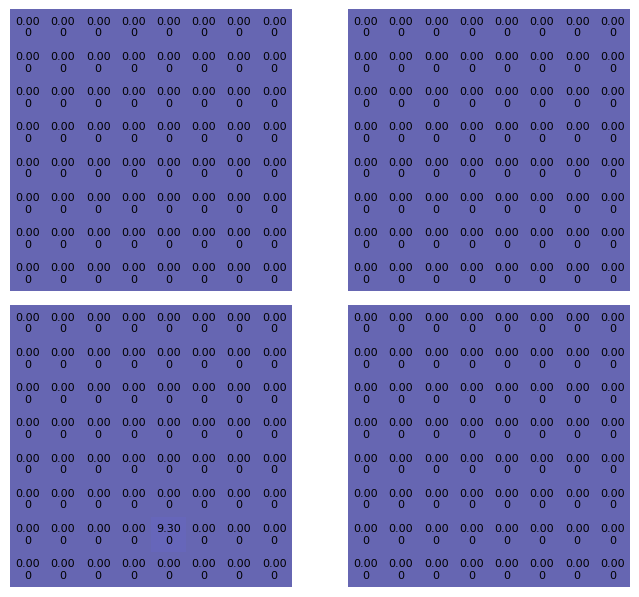

In [50]:
rel, nexttime, length = find_relevents(chunk, lookat)
#print(rel)
print(rel['energy'])
relcal = rel.copy()
relcal['energy'] = energycal.convertenergy(rel['energy'], escalars[rel['id']])
print(lookat, nexttime, length)
print(relcal['energy'])
#print_relevents(relcal)
#make_sipmhm(rel)
make_sipmhm_whole(relcal)
lookat += 1